Data Science with Python Internship –Task 2

Titanic Dataset Analysis
- Name: Swetha Ramesh
- Domain: Data Science with Python
- Company: Maincrafts

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('train.csv')

print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (891, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare     

In [6]:
# Fill missing Age values using median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Remove rows with missing required values
df = df.dropna(subset=['Survived', 'Sex', 'Pclass'])

# Check missing values after cleaning
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
gender_survival = df.groupby('Sex')['Survived'].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival)

Survival Rate by Gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


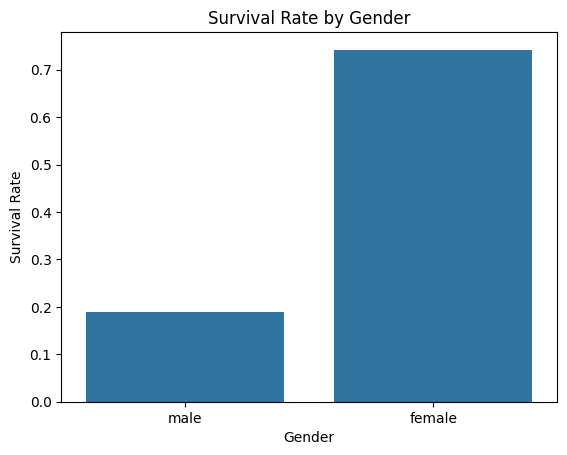

In [8]:
sns.barplot(data=df, x='Sex', y='Survived', errorbar=None)

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')
plt.show()

In [9]:
class_survival = df.groupby('Pclass')['Survived'].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival)

Survival Rate by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


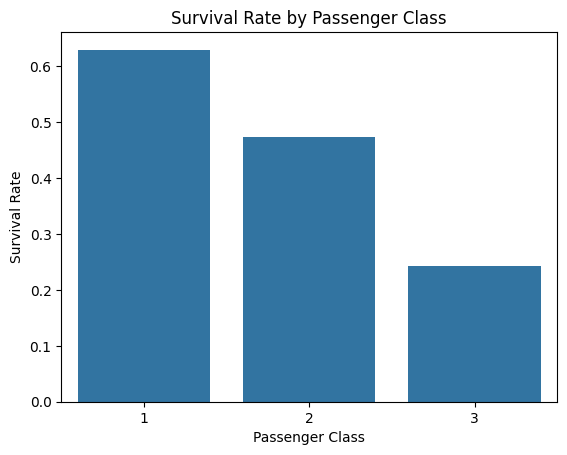

In [10]:
sns.barplot(data=df, x='Pclass', y='Survived', errorbar=None)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

In [11]:
age_bins = [0, 12, 18, 35, 60, 100]

age_labels = ['Child (0-12)', 'Teen (13-18)', 'Adult (19-35)',
              'Middle-aged (36-60)', 'Senior (Above 60)']

df['AgeGroup'] = pd.cut(df['Age'], bins=age_bins,
                        labels=age_labels, include_lowest=True)

age_survival = df.groupby('AgeGroup', observed=False)['Survived'].mean() * 100

print("Survival Rate by Age Group:")
print(age_survival)

Survival Rate by Age Group:
AgeGroup
Child (0-12)           57.971014
Teen (13-18)           42.857143
Adult (19-35)          35.327103
Middle-aged (36-60)    40.000000
Senior (Above 60)      22.727273
Name: Survived, dtype: float64


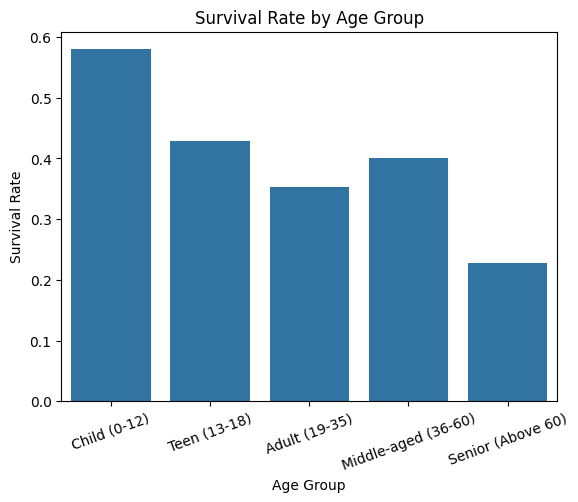

In [12]:
sns.barplot(data=df, x='AgeGroup', y='Survived', errorbar=None)

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.xticks(rotation=20)
plt.show()

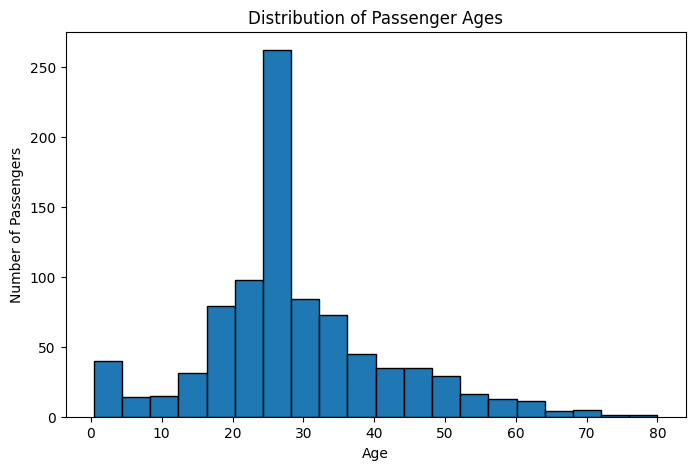

In [13]:
plt.figure(figsize=(8,5))

plt.hist(df['Age'], bins=20, edgecolor='black')

plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

Conclusion
The Titanic dataset was analyzed using Python, Pandas, Matplotlib and Seaborn. Missing values in the Age column were handled using the median method.

The analysis produced the following observations:
1. Gender: Females had a higher survival rate (74.20%) compared to males (18.89%).
2. Passenger Class: First-class passengers had the highest survival rate (62.96%), while third-class passengers had the lowest (24.24%).
3. Age Group: Children (0–12 years) had the highest survival rate (57.97%), while senior passengers had the lowest (22.73%).
4. Visualization: Bar charts and a histogram were used to understand survival patterns and passenger age distribution.
Overall, the analysis shows that gender, passenger class and age were associated with survival differences among Titanic passengers.